# Ecobici — 03. Camión: política actual y propuesta (Etapa 3)

En este notebook se agrega el camión al modelo de `modelo.ipynb`:

1. Se reconstruye qué hace hoy el camión en la subred (septiembre 2026, días hábiles).
2. Se mete esa política al modelo y se valida contra los viajes observados.
3. Se plantea el problema de decisión del operador.
4. Se resuelve y se compara la propuesta con la política actual.

Hay que correr antes `modelo.ipynb`: de ahí salen `tasas_modelo.csv` (λ y μ por hora) y `lotes.csv` (tamaño medio de lote). Las funciones `generador` y la lógica de Kolmogorov son las mismas del modelo; aquí `resolver` trabaja en bloques de 30 min para poder poner visitas del camión.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.linalg import expm

DIR_TABLAS, DIR_FIG = Path("outputs/tablas"), Path("outputs/figuras")
SUBRED = {"271-272": "Buenavista", "273-274": "Buenavista", "014": "Reforma", "027": "Reforma", "018": "Reforma"}
ORDEN, HORAS = list(SUBRED), np.arange(5, 24)
COLORES = {"Buenavista": "#d1495b", "Reforma": "#2e86ab"}
PASOS = 60                      # pasos de un minuto por hora
BLOQUE = 30                     # minutos entre posibles visitas del camión
NB = len(HORAS) * PASOS // BLOQUE   # bloques de 30 min en el día (5:00 a 24:00)

# Parámetros estimados en modelo.ipynb
tasas = pd.read_csv(DIR_TABLAS / "tasas_modelo.csv", dtype={"estacion": str})
B = pd.read_csv(DIR_TABLAS / "lotes.csv", dtype={"estacion": str}).set_index(["estacion", "proceso"]).b
DOCKS = tasas.groupby("estacion").docks.first().astype(int)
dias = pd.DatetimeIndex(sorted(pd.read_parquet("data/clean/trips_2026-09.parquet", columns=["fecha", "es_habil"])
                               .query("es_habil").fecha.unique()))
n_dias = len(dias)

def tasas_estacion(est, columna="tasa"):
    """λ por hora (devoluciones), μ por hora (retiros) y docks."""
    t = tasas[tasas.estacion == est].pivot(index="hora", columns="proceso", values=columna).reindex(HORAS).fillna(0)
    return t["devolucion"].to_numpy(), t["retiro"].to_numpy(), int(DOCKS[est])

def lotes_estacion(est):
    return B[(est, "devolucion")], B[(est, "retiro")]

def generador(lam, mu, N, b_dev=1.0, b_ret=1.0):
    """Generador Q con lotes geométricos (media b; b = 1 es una bici a la vez) y tasa de rechazo en cada estado."""
    n = np.arange(N + 1)
    salto = n[None, :] - n[:, None]                                  # j - i
    Q = np.zeros((N + 1, N + 1))
    for tasa, b, signo, borde in [(lam, b_dev, 1, N), (mu, b_ret, -1, 0)]:
        q, k = 1 / b, signo * salto                                   # k = tamaño del salto en el sentido del proceso
        pk = np.where(k >= 1, q * (1 - q) ** np.clip(k - 1, 0, None), 0.0)       # P(lote = k)
        cola = np.where(k >= 1, (1 - q) ** np.clip(k - 1, 0, None), 0.0)         # P(lote >= k): se queda en el borde
        Q += (tasa / b) * np.where(n[None, :] == borde, cola, pk)
    np.fill_diagonal(Q, 0)
    Q -= np.diag(Q.sum(axis=1))
    rech_dev = lam * (1 - 1 / b_dev) ** (N - n)                       # bicis que no caben, por unidad de tiempo
    rech_ret = mu * (1 - 1 / b_ret) ** n                              # retiros sin bici
    return Q, rech_dev, rech_ret

def resolver(est, x0=None, acciones=None, desde=0):
    """Kolmogorov desde el bloque `desde` (bloques de 30 min desde las 5:00) hasta las 24:00. Mismo modelo que modelo.ipynb.
    x0: entero o None (todos los arranques a la vez; cada fila es un arranque).
    acciones: {minuto del día contado desde las 5:00: f(p) -> (p, [dejadas, sacadas])}, para el camión."""
    lam_h, mu_h, N = tasas_estacion(est)
    b_dev, b_ret = lotes_estacion(est)
    p = np.eye(N + 1) if x0 is None else np.eye(N + 1)[x0]
    acciones, forma = acciones or {}, p.shape[:-1]
    rech = np.zeros((NB,) + forma + (2,))                    # por bloque; [..., 0] sin bici, [..., 1] sin dock
    movidas = np.zeros(forma + (2,))                         # [..., 0] dejadas, [..., 1] sacadas
    P_bloque, P_media = [p], np.zeros((len(HORAS),) + p.shape)
    E = None
    for j in range(desde, NB):
        k = j * BLOQUE // PASOS                              # hora del bloque
        if E is None or j * BLOQUE % PASOS == 0:
            Q, r_dev, r_ret = generador(lam_h[k], mu_h[k], N, b_dev, b_ret)
            E = expm(Q / PASOS)
        for m in range(j * BLOQUE, (j + 1) * BLOQUE):
            if m in acciones:
                p, mov = acciones[m](p)
                movidas = movidas + mov
            p_sig = p @ E
            rech[j, ..., 0] += (p + p_sig) @ r_ret / 2 / PASOS
            rech[j, ..., 1] += (p + p_sig) @ r_dev / 2 / PASOS
            P_media[k] += p_sig / PASOS
            p = p_sig
        P_bloque.append(p)
    return {"rech": rech, "movidas": movidas, "P_bloque": P_bloque, "P_media": P_media, "N": N}

def por_hora(rech):
    """Rechazos por bloque -> por hora."""
    return rech.reshape(len(HORAS), PASOS // BLOQUE, *rech.shape[1:]).sum(1)

def reloj(b):
    """Frontera de bloque -> hora del día como texto."""
    minutos = 5 * 60 + b * BLOQUE
    return f"{minutos // 60}:{minutos % 60:02d}"

def mover(p, cantidad, N):
    """El camión deja `cantidad` bicis (o las saca si es negativa); lo que no cabe o no hay no se mueve.
    Una cantidad fraccionaria se reparte entre los dos enteros vecinos."""
    n, k = np.arange(N + 1), int(np.floor(cantidad))
    nuevo, mov = np.zeros_like(p), 0
    for kk, peso in [(k, 1 - (cantidad - k)), (k + 1, cantidad - k)]:
        if peso > 0:
            dest = np.clip(n + kk, 0, N)
            T = np.zeros((N + 1, N + 1)); T[n, dest] = 1
            nuevo = nuevo + peso * (p @ T)
            mov = mov + peso * np.stack([p @ np.clip(dest - n, 0, None), p @ np.clip(n - dest, 0, None)], -1)
    return nuevo, mov

def dejar_en(p, y, N):
    """Visita: el camión deja la estación con y bicis."""
    n = np.arange(N + 1)
    nuevo = np.zeros_like(p); nuevo[..., y] = 1
    return nuevo, np.stack([p @ np.clip(y - n, 0, None), p @ np.clip(n - y, 0, None)], -1)

## 1. ¿Qué hace hoy el camión?

Los datos no registran al camión, pero se puede reconstruir con el número de bici (mismo método que `eda.ipynb`, sección 4). Si una bici llega a la estación A y su siguiente viaje sale de otra estación B, alguien la movió. Si estuvo quieta más de 24 h se descarta (suele ser mantenimiento).

No se sabe a qué hora exacta se movió, solo que fue entre que llegó a A ($t_1$) y salió de B ($t_2$). Se toma el punto medio. Los movimientos con punto medio entre 5:00 y 23:59 se cuentan como de día, y los demás como de noche (acomodo para el día siguiente).

In [2]:
cols = ["Bici", "Ciclo_Estacion_Retiro", "Ciclo_EstacionArribo", "retiro", "arribo"]
b = pd.read_parquet("data/clean/trips_12m.parquet", columns=cols).sort_values(["Bici", "retiro"]).reset_index(drop=True)
sig = b.groupby("Bici", observed=True)[["Ciclo_Estacion_Retiro", "retiro"]].shift(-1)
desde, hacia = b["Ciclo_EstacionArribo"].astype(str), sig["Ciclo_Estacion_Retiro"].astype(str)
quieta = (sig["retiro"] - b["arribo"]).dt.total_seconds() / 3600
es_mov = sig["retiro"].notna() & (desde != hacia) & quieta.between(0, 24)
mov = pd.DataFrame({"desde": desde[es_mov], "hacia": hacia[es_mov], "t1": b.loc[es_mov, "arribo"], "t2": sig.loc[es_mov, "retiro"]})
del b, sig, desde, hacia, quieta, es_mov

# Hora del movimiento: el punto medio entre que la bici llegó a A y salió de B
mov["tau"] = mov.t1 + (mov.t2 - mov.t1) / 2
mov = mov[(mov.desde.isin(ORDEN) | mov.hacia.isin(ORDEN)) & mov.tau.dt.normalize().isin(dias)]
mov["hora"] = mov.tau.dt.hour
mov["franja"] = np.where(mov.hora.between(5, 23), "día", "noche")
ventana = (mov.t2 - mov.t1).dt.total_seconds() / 3600

saca = mov[mov.desde.isin(ORDEN)].groupby(["desde", "franja"]).size().unstack(fill_value=0) / n_dias
deja = mov[mov.hacia.isin(ORDEN)].groupby(["hacia", "franja"]).size().unstack(fill_value=0) / n_dias
camion = pd.DataFrame({"grupo": pd.Series(SUBRED),
                       "saca (día)": saca["día"], "deja (día)": deja["día"],
                       "saca (noche)": saca["noche"], "deja (noche)": deja["noche"]}).reindex(ORDEN)
camion.loc["Total"] = camion.drop(columns="grupo").sum()
camion.to_csv(DIR_TABLAS / "camion_actual.csv")

saca_h = mov[mov.desde.isin(ORDEN)].groupby(["desde", "hora"]).size().unstack(fill_value=0) \
             .reindex(index=ORDEN, columns=HORAS, fill_value=0) / n_dias
deja_h = mov[mov.hacia.isin(ORDEN)].groupby(["hacia", "hora"]).size().unstack(fill_value=0) \
             .reindex(index=ORDEN, columns=HORAS, fill_value=0) / n_dias
pd.concat({"saca": saca_h, "deja": deja_h}, names=["tipo", "estacion"]).round(2).to_csv(DIR_TABLAS / "camion_actual_hora.csv")

print(f"Movimientos que tocan la subred en los {n_dias} días hábiles: {len(mov):,}. "
      f"Tiempo entre que la bici llega a A y sale de B: mediana {ventana.median():.1f} h, "
      f"{(ventana <= 3).mean():.0%} en 3 h o menos.")
camion.round(1)

Movimientos que tocan la subred en los 19 días hábiles: 18,146. Tiempo entre que la bici llega a A y sale de B: mediana 1.5 h, 75% en 3 h o menos.


,grupo,saca (día),deja (día),saca (noche),deja (noche)
271-272,Buenavista,376.2,233.0,45.1,15.8
273-274,Buenavista,93.4,40.9,19.9,7.7
014,Reforma,93.1,40.8,1.4,0.1
027,Reforma,49.5,31.5,1.2,0.3
018,Reforma,58.8,31.5,0.6,0.0
Total,NaN,670.9,377.8,68.2,23.9


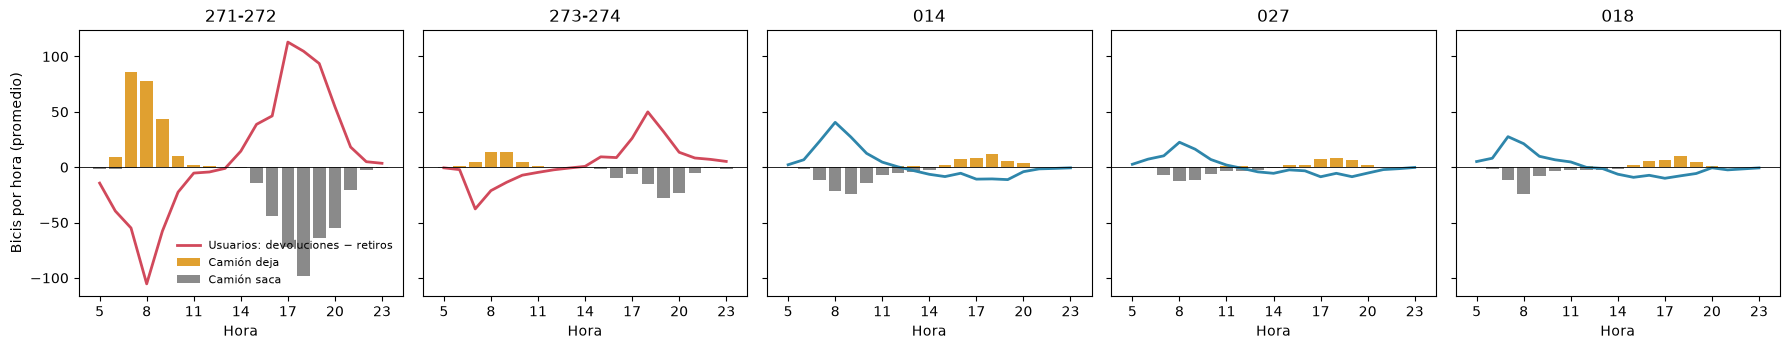

In [3]:
fig, ax = plt.subplots(1, 5, figsize=(18, 3.6), sharey=True)
for a, est in zip(ax, ORDEN):
    lam, mu, _ = tasas_estacion(est, "tasa_obs")
    a.bar(HORAS, deja_h.loc[est], color="#e0a030", label="Camión deja")
    a.bar(HORAS, -saca_h.loc[est], color="#8a8a8a", label="Camión saca")
    a.plot(HORAS, lam - mu, color=COLORES[SUBRED[est]], lw=2, label="Usuarios: devoluciones − retiros")
    a.axhline(0, color="black", lw=0.6); a.set_title(est); a.set_xlabel("Hora"); a.set_xticks(range(5, 24, 3))
ax[0].set_ylabel("Bicis por hora (promedio)"); ax[0].legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(DIR_FIG / "camion_actual.png", dpi=150, bbox_inches="tight"); plt.show()

**Resultados**

- En los 19 días hábiles hay 18,146 movimientos que tocan la subred. La ventana entre $t_1$ y $t_2$ tiene mediana de 1.5 h, así que la hora asignada es razonablemente precisa.
- De día el camión saca 671 bicis y deja 378 en las 5 estaciones; de noche mueve 92 más.
- La 271-272 concentra el trabajo: el camión le deja bicis de 6 a 10 h (hasta 86 por hora) y le saca de 15 a 21 h (hasta 98 por hora). Es justo el espejo del flujo de los usuarios.
- En Reforma pasa lo contrario: saca en la mañana y deja en la tarde.

## 2. La política actual dentro del modelo

Se aplica al modelo el neto promedio que movió el camión en cada hora (deja − saca), repartido en partes iguales cada 5 min, porque en las horas pico el camión trabaja de forma casi continua. Si no hay lugar o no hay bicis, esa parte no se mueve.

No se sabe con cuántas bicis arrancan las estaciones a las 5:00. A cada política se le da su mejor arranque, así la comparación no favorece a la propuesta por ese lado.

Medidas de desempeño, todas por día:
- rechazos sin bici y sin dock;
- % de la demanda atendida;
- horas esperadas vacía y llena ($\sum_h P(\text{vacía en } h)$);
- bicis que deja y saca el camión.

In [4]:
CADA = 5    # minutos

def acciones_actual(est):
    """Política actual: el neto promedio que movió el camión en cada hora, repartido en partes iguales cada 5 min
    (el camión real trabaja de forma casi continua en las horas pico)."""
    N, neto = int(DOCKS[est]), deja_h.loc[est] - saca_h.loc[est]
    return {k * PASOS + m: (lambda p, c=neto.iloc[k] * CADA / PASOS: mover(p, c, N))
            for k in range(len(HORAS)) if neto.iloc[k] != 0 for m in range(CADA // 2, PASOS, CADA)}

def medidas(est, r, lam, mu):
    """Medidas de desempeño de un día ya resuelto (x0 fijo)."""
    N = r["N"]
    return {"sin bici": r["rech"][..., 0].sum(), "sin dock": r["rech"][..., 1].sum(),
            "rechazos": r["rech"].sum(), "% demanda atendida": 100 * (1 - r["rech"].sum() / (lam.sum() + mu.sum())),
            "horas vacía": r["P_media"][:, 0].sum(), "horas llena": r["P_media"][:, N].sum(),
            "bicis dejadas": r["movidas"][0], "bicis sacadas": r["movidas"][1]}

politicas, sol = {}, {}
for est in ORDEN:
    lam, mu, N = tasas_estacion(est)
    for nombre, acc in [("sin camión", None), ("actual", acciones_actual(est))]:
        todos = resolver(est, None, acc)
        x0 = int(todos["rech"].sum(axis=(0, 2)).argmin())        # mejor arranque para cada política
        r = resolver(est, x0, acc)
        sol[(nombre, est)] = r
        politicas[(nombre, est)] = {"x0": x0, **medidas(est, r, lam, mu)}

tabla = pd.DataFrame(politicas).T
tabla.index.names = ["política", "estación"]
tabla.groupby(level="política", sort=False)[["rechazos", "bicis dejadas", "bicis sacadas"]].sum().round(0)

,rechazos,bicis dejadas,bicis sacadas
política,,,
sin camión,1089.0,0.0,0.0
actual,207.0,357.0,651.0


### 2.1 Validación con el camión

En la Etapa 2 no se podía comparar el modelo con los viajes observados porque en los datos sí hay camión. Ahora sí se puede: los viajes que completa el modelo con la política actual (demanda − rechazos) deberían parecerse a los observados.

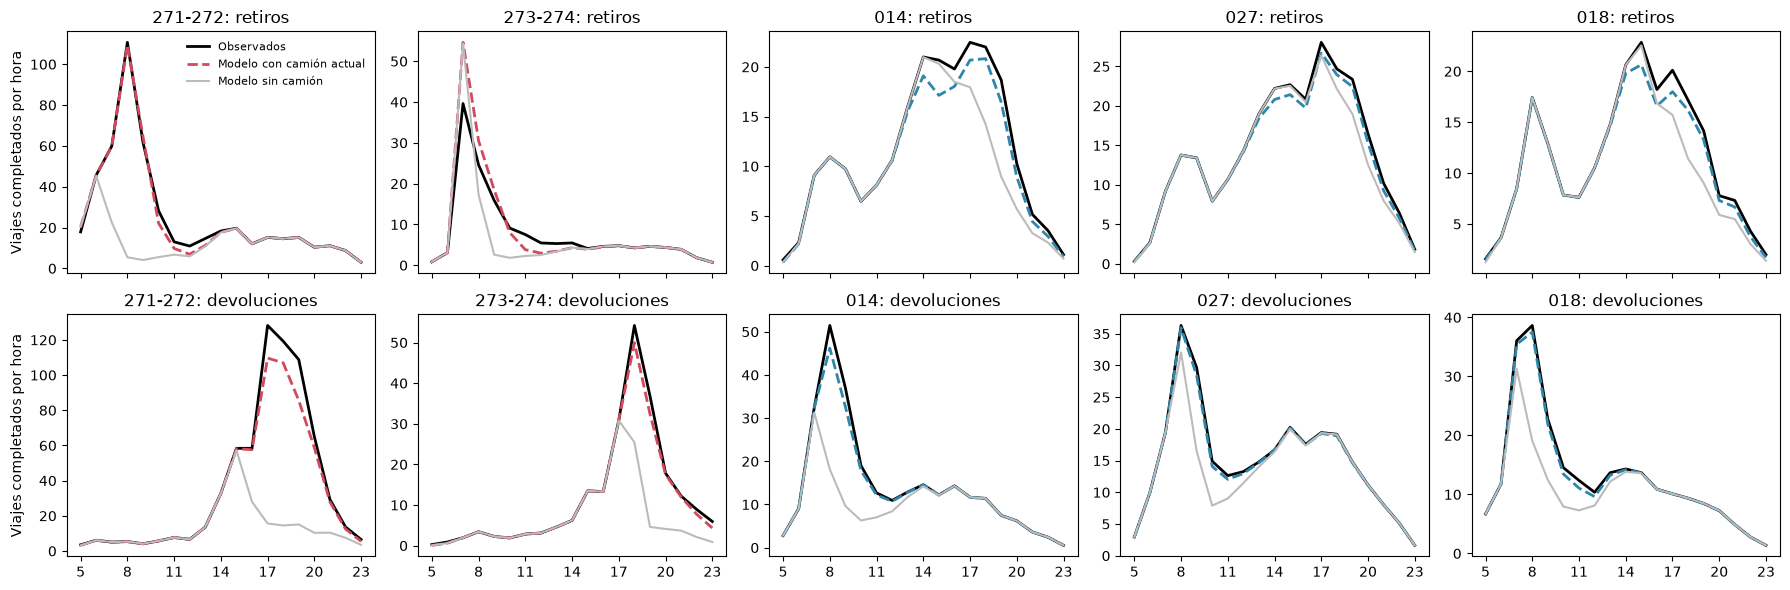

,estación,proceso,observados por día,modelo con camión,modelo sin camión,error medio por hora (con camión),error medio por hora (sin camión)
0,271-272,retiros,491.2,477.7,254.2,1.3,12.7
1,271-272,devoluciones,678.1,612.7,252.5,3.4,22.4
2,273-274,retiros,150.2,163.0,125.6,1.8,2.8
3,273-274,devoluciones,221.1,208.5,125.4,0.7,5.0
4,014,retiros,218.6,202.4,186.5,0.9,1.7
5,014,devoluciones,272.7,260.9,188.4,0.6,4.4
6,027,retiros,268.2,257.6,251.1,0.6,0.9
7,027,devoluciones,287.8,283.5,256.3,0.2,1.7
8,018,retiros,219.4,208.3,196.5,0.6,1.2
9,018,devoluciones,250.0,243.5,199.4,0.3,2.7


In [5]:
# Con el camión actual, los viajes que completa el modelo deben parecerse a los que se observan
filas = []
fig, ax = plt.subplots(2, 5, figsize=(18, 6), sharex=True)
for j, est in enumerate(ORDEN):
    lam, mu, N = tasas_estacion(est)
    lam_obs, mu_obs, _ = tasas_estacion(est, "tasa_obs")
    for i, (proc, dem, obs, col) in enumerate([("retiros", mu, mu_obs, 0), ("devoluciones", lam, lam_obs, 1)]):
        hechos = {p: dem - por_hora(sol[(p, est)]["rech"])[:, col] for p in ["sin camión", "actual"]}
        a = ax[i, j]
        a.plot(HORAS, obs, color="black", lw=2, label="Observados")
        a.plot(HORAS, hechos["actual"], color=COLORES[SUBRED[est]], lw=2, ls="--", label="Modelo con camión actual")
        a.plot(HORAS, hechos["sin camión"], color="#bbbbbb", lw=1.5, label="Modelo sin camión")
        a.set_title(f"{est}: {proc}"); a.set_xticks(range(5, 24, 3))
        filas.append({"estación": est, "proceso": proc, "observados por día": obs.sum(),
                      "modelo con camión": hechos["actual"].sum(), "modelo sin camión": hechos["sin camión"].sum(),
                      "error medio por hora (con camión)": np.abs(hechos["actual"] - obs).mean(),
                      "error medio por hora (sin camión)": np.abs(hechos["sin camión"] - obs).mean()})
ax[0, 0].set_ylabel("Viajes completados por hora"); ax[1, 0].set_ylabel("Viajes completados por hora")
ax[0, 0].legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(DIR_FIG / "camion_validacion.png", dpi=150, bbox_inches="tight"); plt.show()
validacion = pd.DataFrame(filas)
validacion.round(1).to_csv(DIR_TABLAS / "camion_validacion.csv", index=False)
validacion.round(1)

**Resultados**

- Con el camión, el modelo reproduce los viajes observados. En la 271-272 da 478 retiros por día contra 491 observados (sin camión daría 254) y 613 devoluciones contra 678 (sin camión, 253).
- El error medio por hora baja mucho al meter el camión: en la 271-272 pasa de 12.7 a 1.3 en retiros y de 22.4 a 3.4 en devoluciones.
- Donde más falla es en las devoluciones de la 271-272 de 17 a 19 h: el modelo deja entrar menos bicis que la realidad. El camión real reacciona cuando ve la estación llena, y aquí solo se usa su promedio, así que la política actual sale un poco peor de lo que es.
- Con el camión actual, el modelo da 207 rechazos por día en la subred (sin camión, 1,089).

## 3. Problema de decisión

Lo que decide el operador en cada estación $i$:
- $x_{0,i}$: con cuántas bicis arranca a las 5:00 (se acomoda en la noche);
- las visitas del día: pares $(t, y)$, donde a la hora $t \in \{5{:}30, 6{:}00, \dots, 23{:}30\}$ el camión deja la estación con $y$ bicis (si tiene más, saca; si tiene menos, deja).

Objetivo:

$$\min \; \sum_i E[R_i] + w \sum_i E[M_i]$$

donde $R_i$ son los rechazos del día (sin bici + sin dock) y $M_i$ las bicis que mueve el camión en la estación durante el día. $w$ es el costo de mover una bici medido en rechazos; se varía para ver el intercambio entre ambos.

Restricciones:
- a lo más $K$ visitas por estación al día;
- $\sum_i E[M_i] \le$ lo que mueve hoy el camión en el modelo (1,008 bicis por día). Así la mejora no viene de mover más bicis, sino de moverlas mejor.

Fuera del problema por ahora: capacidad del camión por visita (se revisa después), ruta entre estaciones, número de camiones y el resto del sistema.

Cómo se resuelve. Con el supuesto de estaciones independientes, el problema se separa por estación. Dentro de una estación, después de una visita el número de bicis se conoce ($y$), así que el día se parte en tramos independientes. Esto permite una programación dinámica exacta:

$$F_k(t, y') = \min_{s < t,\; y} \; F_{k-1}(s, y) + R(s, y \to t) + w \, E\big[\,|X_t - y'| \;\big|\; X_s = y\big]$$

$F_k(t, y')$ es el mejor costo hasta $t$ usando $k$ visitas y dejando $y'$ bicis en $t$, y $R(s, y \to t)$ son los rechazos esperados entre $s$ y $t$ arrancando con $y$ (Kolmogorov). Se resuelve para $K \in \{2, 4, 8, 16\}$ y $w \in \{0.1, 0.25, 0.5, 0.75\}$, y se elige la combinación con menos rechazos que no mueva más bicis que hoy.

In [6]:
def preparar(est):
    """Para cada bloque de arranque a y cada nivel y: rechazos acumulados y distribución en cada frontera posterior."""
    seg = [resolver(est, None, desde=a) for a in range(NB)]
    rej = [np.vstack([np.zeros(int(DOCKS[est]) + 1), np.cumsum(s["rech"][a:].sum(-1), axis=0)]) for a, s in enumerate(seg)]
    return {"N": int(DOCKS[est]), "rej": rej, "dist": [s["P_bloque"] for s in seg]}

def optimizar(pre, K, w):
    """Programación dinámica exacta: mejor x0 y hasta K visitas (cada 30 min, de 5:30 a 23:30)
    que minimizan rechazos esperados + w · bicis movidas esperadas."""
    N, rej, dist = pre["N"], pre["rej"], pre["dist"]
    dif = np.abs(np.arange(N + 1)[:, None] - np.arange(N + 1)[None, :])
    F = np.full((K + 1, NB, N + 1), np.inf); F[0, 0] = 0           # F[k, b, y]: costo hasta la frontera b, dejando y bicis
    PA = np.zeros((K + 1, NB, N + 1), dtype=int); PY = np.zeros_like(PA)
    cols = np.arange(N + 1)
    for k in range(K):
        for b in range(1, NB):
            for a in range(b):
                if not np.isfinite(F[k, a]).any():
                    continue
                c = F[k, a][:, None] + rej[a][b - a][:, None] + w * (dist[a][b - a] @ dif)
                i = c.argmin(0); v = c[i, cols]
                mejor = v < F[k + 1, b]
                F[k + 1, b, mejor] = v[mejor]; PA[k + 1, b, mejor] = a; PY[k + 1, b, mejor] = i[mejor]
    mejor = (np.inf, None)
    for k in range(K + 1):
        for a in range(NB):
            tot = F[k, a] + rej[a][NB - a]
            if tot.min() < mejor[0]:
                mejor = (tot.min(), (k, a, int(tot.argmin())))
    k, a, y = mejor[1]
    visitas = []
    while k > 0:
        visitas.append((a, y)); a, y = PA[k, a, y], PY[k, a, y]; k -= 1
    return {"x0": int(y), "visitas": visitas[::-1]}                 # visitas = [(frontera, nivel), ...]

def evaluar(est, plan):
    """Resuelve el día con el plan."""
    N = int(DOCKS[est])
    acc = {b * BLOQUE: (lambda p, y=y: dejar_en(p, y, N)) for b, y in plan["visitas"]}
    return resolver(est, plan["x0"], acc)

pre = {est: preparar(est) for est in ORDEN}

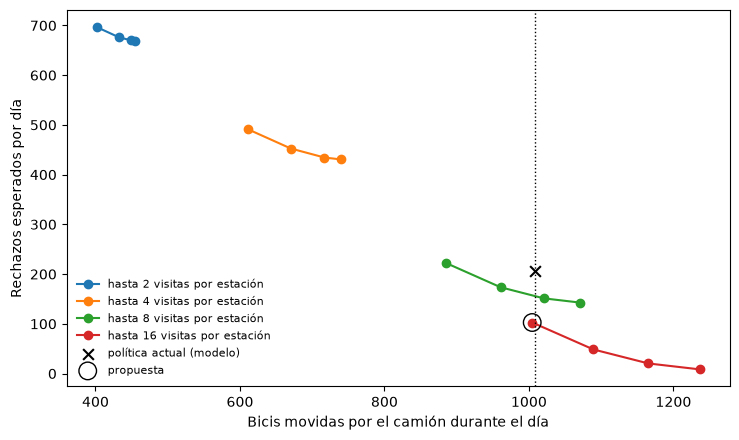

Política actual en el modelo: 1,008 bicis movidas en el día. Propuesta: K = 16, w = 0.75.


K: bicis movidas,2,4,8,16
w,,,,
0.10,455.0,740.0,1071.0,1237.0
0.25,449.0,717.0,1021.0,1165.0
0.50,432.0,671.0,961.0,1089.0
0.75,402.0,611.0,885.0,1005.0


K: rechazos,2,4,8,16
w,,,,
0.10,669.0,430.0,143.0,8.0
0.25,670.0,434.0,151.0,20.0
0.50,676.0,452.0,174.0,48.0
0.75,697.0,491.0,222.0,103.0


In [7]:
# Frontera: rechazos contra bicis movidas, según visitas máximas por estación (K) y costo por bici movida (w)
filas, planes = [], {}
for K in [2, 4, 8, 16]:
    for w in [0.1, 0.25, 0.5, 0.75]:
        rech, movidas = 0.0, 0.0
        for est in ORDEN:
            plan = optimizar(pre[est], K, w)
            r = evaluar(est, plan)
            planes[(K, w, est)] = (plan, r)
            rech += r["rech"].sum(); movidas += r["movidas"].sum()
        filas.append({"K": K, "w": w, "rechazos": rech, "bicis movidas (día)": movidas})
frontera = pd.DataFrame(filas)
frontera.round(1).to_csv(DIR_TABLAS / "camion_frontera.csv", index=False)

act = tabla.xs("actual", level="política")
mov_actual = act[["bicis dejadas", "bicis sacadas"]].sum().sum()       # lo que mueve la política actual dentro del modelo
ok = frontera[frontera["bicis movidas (día)"] <= mov_actual]
elegido = ok.sort_values(["rechazos", "K"]).iloc[0]
K_PROP, W_PROP = int(elegido.K), float(elegido.w)

fig, ax = plt.subplots(figsize=(7.5, 4.5))
for K, g in frontera.groupby("K"):
    ax.plot(g["bicis movidas (día)"], g.rechazos, marker="o", label=f"hasta {K} visitas por estación")
ax.axvline(mov_actual, color="black", ls=":", lw=1)
ax.scatter(mov_actual, act.rechazos.sum(), color="black", marker="x", s=60, zorder=3, label="política actual (modelo)")
ax.scatter(elegido["bicis movidas (día)"], elegido.rechazos, s=160, facecolor="none", edgecolor="black", zorder=3, label="propuesta")
ax.set_xlabel("Bicis movidas por el camión durante el día"); ax.set_ylabel("Rechazos esperados por día"); ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(DIR_FIG / "camion_frontera.png", dpi=150, bbox_inches="tight"); plt.show()
print(f"Política actual en el modelo: {mov_actual:,.0f} bicis movidas en el día. Propuesta: K = {K_PROP}, w = {W_PROP}.")
display(frontera.pivot(index="w", columns="K", values="bicis movidas (día)").round(0).rename_axis(columns="K: bicis movidas"))
frontera.pivot(index="w", columns="K", values="rechazos").round(0).rename_axis(columns="K: rechazos")

**Resultados**

- Con pocas visitas no se le gana a la política actual: con hasta 4 visitas por estación quedan más de 430 rechazos.
- La elegida es hasta 16 visitas por estación con $w = 0.75$: 103 rechazos por día moviendo 1,005 bicis, casi las mismas que hoy (1,008).
- Si se permite mover más bicis que hoy, los rechazos bajan todavía más (8 rechazos con 1,237 bicis movidas).

In [8]:
filas, visitas = [], []
for est in ORDEN:
    lam, mu, N = tasas_estacion(est)
    plan, r = planes[(K_PROP, W_PROP, est)]
    sol[("propuesta", est)] = r
    politicas[("propuesta", est)] = {"x0": plan["x0"], **medidas(est, r, lam, mu)}
    for b, y in plan["visitas"]:
        p = r["P_bloque"][b]                                   # distribución justo antes de la visita
        d = np.arange(N + 1) - y
        orden = np.argsort(np.abs(d)); acum = np.cumsum(p[orden])
        visitas.append({"estación": est, "hora": reloj(b), "frontera": b, "deja la estación con": y,
                        "bicis que deja (prom.)": p @ np.clip(-d, 0, None), "bicis que saca (prom.)": p @ np.clip(d, 0, None),
                        "bicis movidas (p95)": int(np.abs(d)[orden][np.searchsorted(acum, 0.95)])})
plan_visitas = pd.DataFrame(visitas)
plan_visitas.round(1).to_csv(DIR_TABLAS / "camion_propuesta.csv", index=False)

tabla = pd.DataFrame(politicas).T
tabla.index.names = ["política", "estación"]
tabla.round(2).to_csv(DIR_TABLAS / "camion_politicas.csv")
noche = sum(sol[("propuesta", e)]["P_bloque"][-1] @ np.abs(np.arange(int(DOCKS[e]) + 1) - politicas[("propuesta", e)]["x0"])
            for e in ORDEN)
print("Arranque (x0) de la propuesta:", {e: politicas[("propuesta", e)]["x0"] for e in ORDEN})
print(f"Visitas por estación: {plan_visitas['estación'].value_counts().reindex(ORDEN).to_dict()}")
print(f"Para volver al arranque, en la noche hay que mover en promedio {noche:.0f} bicis "
      f"(hoy el camión mueve {camion.loc['Total', ['saca (noche)', 'deja (noche)']].sum():.0f} de noche).")
plan_visitas.drop(columns="frontera").round(1)

Arranque (x0) de la propuesta: {'271-272': 74, '273-274': 70, '014': 0, '027': 0, '018': 0}
Visitas por estación: {'271-272': 16, '273-274': 12, '014': 8, '027': 2, '018': 5}
Para volver al arranque, en la noche hay que mover en promedio 18 bicis (hoy el camión mueve 92 de noche).


,estación,hora,deja la estación con,bicis que deja (prom.),bicis que saca (prom.),bicis movidas (p95)
0,271-272,7:00,72,54.4,0.0,72
1,271-272,8:00,72,54.6,0.0,72
2,271-272,8:30,72,52.5,0.0,70
3,271-272,9:00,65,45.5,0.0,63
4,271-272,9:30,57,26.7,0.0,41
5,271-272,10:30,24,15.3,0.2,24
6,271-272,16:00,6,0.0,52.0,68
7,271-272,17:00,3,0.0,49.2,67
8,271-272,17:30,3,0.0,56.1,71
9,271-272,18:00,4,0.0,55.1,70


**La propuesta**

- Arranque: Buenavista llena (74 y 70 bicis) y Reforma vacía.
- Visitas por estación: 16 a la 271-272, 12 a la 273-274, 8 a la 014, 5 a la 018 y 2 a la 027.
- La 271-272 se rellena cada 30 a 60 min de 7:00 a 10:30 (unas 54 bicis por visita al principio) En la tarde se vacía: de 16:00 a 19:30 se deja con 3 a 7 bicis, y después el nivel objetivo sube hasta 51 a las 21:00, cuando ya llegan menos devoluciones.
- La 273-274 baja su nivel objetivo durante la mañana (de 33 a 12 bicis) y lo sube en la noche.
- En Reforma: vaciar de 7:30 a 10:00 y dejar algunas bicis en la tarde.
- Para volver al arranque de la mañana siguiente hay que mover en promedio 18 bicis en la noche; hoy el camión mueve 92.

In [9]:
# ¿De dónde salen las bicis? Neto que deja el camión en cada horario de visita (positivo = entran bicis a la estación)
pv = plan_visitas.assign(grupo=plan_visitas["estación"].map(SUBRED),
                         neto=plan_visitas["bicis que deja (prom.)"] - plan_visitas["bicis que saca (prom.)"])
neto = pv.pivot_table(index="frontera", columns="grupo", values="neto", aggfunc="sum", fill_value=0)
neto["subred"] = neto.sum(axis=1)
neto.index = [reloj(b) for b in neto.index]
print(f"En el día la propuesta deja {pv['bicis que deja (prom.)'].sum():.0f} bicis y saca "
      f"{pv['bicis que saca (prom.)'].sum():.0f}: el neto con el resto del sistema es {neto.subred.sum():+.0f} bicis.")
neto.round(1)

En el día la propuesta deja 354 bicis y saca 650: el neto con el resto del sistema es -296 bicis.


grupo,Buenavista,Reforma,subred
7:00,54.4,0.0,54.4
7:30,0.0,-29.1,-29.1
8:00,73.3,-21.4,51.9
8:30,63.4,-38.9,24.6
9:00,55.4,-22.5,32.9
9:30,34.6,-19.1,15.5
10:00,6.7,-8.3,-1.6
10:30,20.8,0.0,20.8
16:00,-52.0,14.6,-37.4
16:30,0.0,16.2,16.2


**Resultados**

- En la mañana las bicis que se sacan de Reforma (de 8 a 39 por visita) pueden cubrir parte de lo que necesita Buenavista (de 7 a 73 por visita). El resto tiene que venir de fuera de la subred.
- En la tarde la subred tiene bicis de sobra (Buenavista recibe más de lo que caben) y el camión las saca hacia el resto del sistema. En el día, el neto es de unas 296 bicis que salen de la subred: es el excedente que dejan los usuarios.

### 4.1 Capacidad del camión

La programación dinámica no limita cuántas bicis se mueven por visita: en la 271-272 algunas visitas mueven 70 o más. Aquí se evalúa el mismo plan con un camión que carga a lo más $C$ bicis por visita.

In [10]:
def dejar_en_cap(p, y, N, C):
    """Visita con un camión que carga a lo más C bicis: se acerca a y sin mover más de C."""
    n = np.arange(N + 1)
    dest = np.clip(y, n - C, n + C)
    T = np.zeros((N + 1, N + 1)); T[n, dest] = 1
    return p @ T, np.stack([p @ np.clip(dest - n, 0, None), p @ np.clip(n - dest, 0, None)], -1)

filas = []
for C in [20, 30, 40, 60, None]:
    rech = movidas = 0
    for est in ORDEN:
        N, plan = int(DOCKS[est]), planes[(K_PROP, W_PROP, est)][0]
        acc = {b * BLOQUE: (lambda p, y=y, C=C: dejar_en(p, y, N) if C is None else dejar_en_cap(p, y, N, C))
               for b, y in plan["visitas"]}
        r = resolver(est, plan["x0"], acc)
        rech += r["rech"].sum(); movidas += r["movidas"].sum()
    filas.append({"capacidad por visita": "sin límite" if C is None else C, "rechazos": rech, "bicis movidas": movidas})
capacidad = pd.DataFrame(filas).set_index("capacidad por visita")
capacidad["rechazos actual"] = tabla.xs("actual", level="política").rechazos.sum()
capacidad.round(0)

,rechazos,bicis movidas,rechazos actual
capacidad por visita,,,
20,454.0,651.0,207.0
30,311.0,795.0,207.0
40,197.0,910.0,207.0
60,105.0,1003.0,207.0
sin límite,103.0,1005.0,207.0


**Resultados**

- La mejora depende de la capacidad. Con 60 bicis por visita la propuesta casi no pierde (105 rechazos), con 40 queda apenas mejor que hoy (197 contra 207) y con 20 o 30 queda peor.
- Para que la propuesta funcione hace falta un camión grande o dos camiones en Buenavista en las horas pico. Hay que conseguir la capacidad real de los camiones de Ecobici y meterla como restricción en el problema.

## 5. Comparación

Medidas de desempeño de las tres políticas: sin camión, actual y propuesta (sin límite de capacidad).

Rechazos por día: sin camión 1,089, actual 207, propuesta 103 (50% menos que la política actual).


,rechazos,sin bici,sin dock,bicis dejadas,bicis sacadas,% demanda atendida
política,,,,,,
sin camión,1089.0,401.3,687.7,0.0,0.0,65.2
actual,206.8,106.3,100.5,357.0,650.9,93.4
propuesta,102.7,56.3,46.3,354.5,650.1,96.7


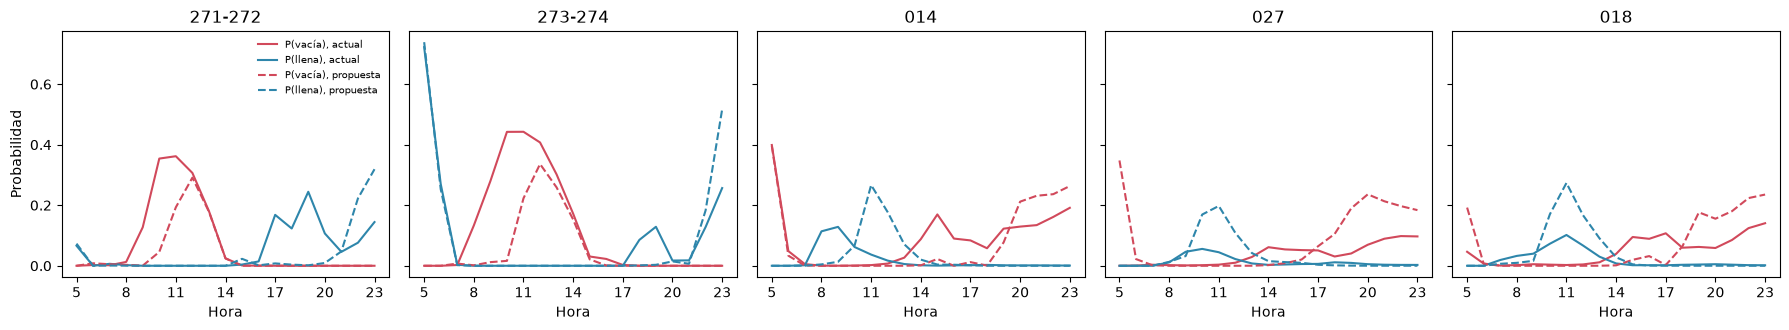

política sin camión                                                   \
           rechazos sin bici sin dock % demanda atendida horas vacía   
estación                                                               
014           116.4     32.1     84.3               76.3         3.1   
018            73.5     22.9     50.6               84.3         2.2   
027            48.6     17.1     31.5               91.3         1.6   
271-272       688.1    262.4    425.6               42.4         4.4   
273-274       162.4     66.8     95.6               60.7         3.9   

política                                           actual           ...  \
         horas llena bicis dejadas bicis sacadas rechazos sin bici  ...   
estación                                                            ...   
014              2.8           0.0           0.0     28.0     16.2  ...   
018              2.2           0.0           0.0     17.6     11.1  ...   
027              1.5           0.0           0.0     14.9     10.6  ...   
271-272          5.4           0.0           0.0    104.3     38.9  ...   
273-274          5.4           0.0           0.0     41.9     29.4  ...   

política                             propuesta                    \
         bicis dejadas bicis sacadas  rechazos sin bici sin dock   
estación                                                           
014               37.1          89.0      16.4      7.2      9.3   
018               28.5          55.6      20.0      9.3     10.7   
027               27.6          45.6      27.4     17.8      9.6   
271-272          225.7         370.3      25.2     14.3     10.9   
273-274           38.1          90.4      13.6      7.8      5.9   

política                                                           \
         % demanda atendida horas vacía horas llena bicis dejadas   
estación                                                            
014                    96.7         1.5         0.6          28.2   
018                    95.7         1.3         0.8          16.6   
027                    95.1         1.6         0.6           0.4   
271-272                97.9         0.8         0.7         249.2   
273-274                96.7         1.0         1.7          60.0   

política                
         bicis sacadas  
estación                
014               76.2  
018               41.2  
027               23.2  
271-272          417.5  
273-274           91.9  

[5 rows x 24 columns]

In [11]:
orden = ["sin camión", "actual", "propuesta"]
cols = ["rechazos", "sin bici", "sin dock", "% demanda atendida", "horas vacía", "horas llena", "bicis dejadas", "bicis sacadas"]
porest = tabla[cols].unstack("política").swaplevel(axis=1)[orden]
total = tabla.groupby(level="política")[["rechazos", "sin bici", "sin dock", "bicis dejadas", "bicis sacadas"]].sum().reindex(orden)
dem = sum(tasas_estacion(e)[0].sum() + tasas_estacion(e)[1].sum() for e in ORDEN)
total["% demanda atendida"] = 100 * (1 - total.rechazos / dem)
mejora = 1 - total.loc["propuesta", "rechazos"] / total.loc["actual", "rechazos"]
print(f"Rechazos por día: sin camión {total.loc['sin camión', 'rechazos']:,.0f}, actual {total.loc['actual', 'rechazos']:,.0f}, "
      f"propuesta {total.loc['propuesta', 'rechazos']:,.0f} ({mejora:.0%} menos que la política actual).")
display(total.round(1))

fig, ax = plt.subplots(1, 5, figsize=(18, 3.4), sharey=True)
for a, est in zip(ax, ORDEN):
    N = int(DOCKS[est])
    for pol, ls in [("actual", "-"), ("propuesta", "--")]:
        P = sol[(pol, est)]["P_media"]
        a.plot(HORAS, P[:, 0], color="#d1495b", ls=ls, label=f"P(vacía), {pol}")
        a.plot(HORAS, P[:, N], color="#2e86ab", ls=ls, label=f"P(llena), {pol}")
    a.set_title(est); a.set_xlabel("Hora"); a.set_xticks(range(5, 24, 3))
ax[0].set_ylabel("Probabilidad"); ax[0].legend(frameon=False, fontsize=7)
fig.tight_layout(); fig.savefig(DIR_FIG / "camion_comparacion.png", dpi=150, bbox_inches="tight"); plt.show()
porest.round(1)

**Resultados**

- Rechazos por día en la subred: 1,089 sin camión, 207 con la política actual y 103 con la propuesta, la mitad que hoy, moviendo las mismas bicis. La demanda atendida pasa de 93.4 % a 96.7 %.
- Casi toda la mejora está en la 271-272, que baja de 104 a 25 rechazos, y en la 273-274, que baja de 42 a 14.
- En la 027 y la 018 la propuesta queda peor que hoy (27 contra 15 y 20 contra 18): el plan les quita visitas para dárselas a Buenavista. Si eso no se acepta, hay que agregar una restricción de servicio mínimo por estación.

## 6. Límites y pendientes

- **Capacidad y ruta.** No hay límite de bicis por visita ni ruta entre estaciones. Con camiones de 20 a 30 bicis la propuesta no le gana a la política actual (sección 4.1).
- **Política actual aproximada.** Se modela con promedios por hora, no con lo que el camión ve en cada momento; el modelo la hace un poco peor de lo que es (sección 2.1). La mejora de 50 % puede ser algo optimista.
- **La propuesta reacciona al estado.** Deja la estación en un nivel, así que mueve lo que haga falta según cuántas bicis haya. Eso requiere saber el nivel al llegar, algo que hoy el sistema sí puede ver.
- **Hora de los movimientos.** Se toma el punto medio de la ventana entre $t_1$ y $t_2$ (mediana de 1.5 h).
- **Supuestos del modelo.** Siguen los de `modelo.ipynb`: día típico, estaciones independientes, usuario rechazado se pierde.
- **Pendiente para la Etapa 4:** probar la propuesta en meses de demanda alta y baja.